WASSERSTEIN DISTANCE BETWEEN CENTERED GAUSSIANS

 sigma  sigma_k  Exact_W2_Squared  Map_W2_Squared     Map_Error  Quantile_W2_Squared  Quantile_Error
  0.50      1.0            0.2500          0.2500  0.000000e+00               0.2500    2.109649e-09
  0.75      1.0            0.0625          0.0625  0.000000e+00               0.0625    5.274123e-10
  1.00      1.0            0.0000          0.0000  0.000000e+00               0.0000    0.000000e+00
  1.50      1.0            0.2500          0.2500  0.000000e+00               0.2500    2.109649e-09
  2.00      1.0            1.0000          1.0000  0.000000e+00               1.0000    8.438597e-09
  3.00      1.0            4.0000          4.0000  0.000000e+00               4.0000    3.375439e-08
  1.00      0.5            0.2500          0.2500  0.000000e+00               0.2500    2.109649e-09
  2.00      1.5            0.2500          0.2500 -5.551115e-17               0.2500    2.109649e-09
  3.00      2.0            1.0000         

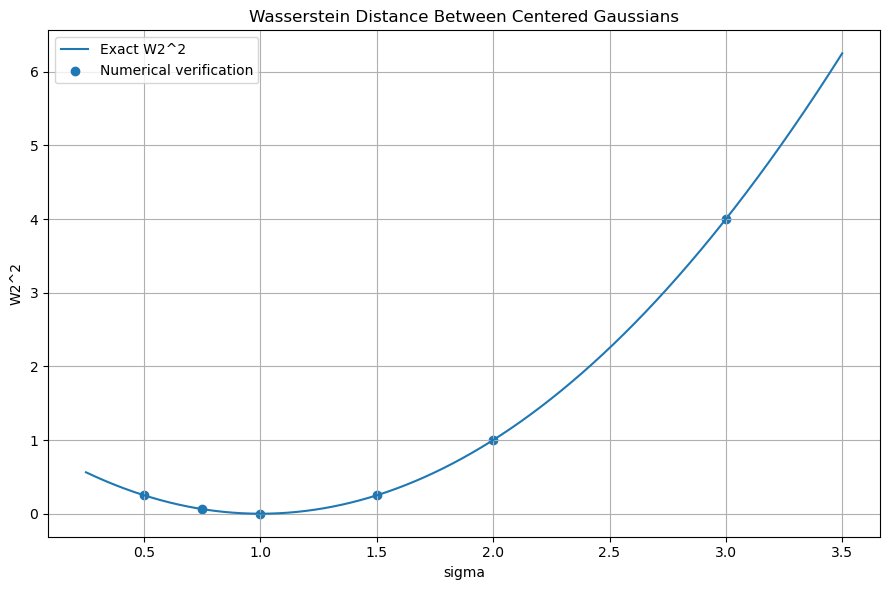


FINAL RESULT

W2^2(N(0,sigma^2), N(0,sigma_k^2))
= (sigma - sigma_k)^2

W2 = |sigma - sigma_k|


In [1]:
# ============================================================
# HOMEWORK 4.2 - PART II
# WASSERSTEIN DISTANCE BETWEEN CENTERED GAUSSIANS
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm


# ============================================================
# GAUSSIAN DENSITY
# ============================================================

def gaussian_density(
    x,
    sigma
):

    return (

        1.0

        /

        (
            np.sqrt(2.0 * np.pi)
            *
            sigma
        )

        *

        np.exp(

            -x**2

            /

            (
                2.0
                *
                sigma**2
            )
        )
    )


# ============================================================
# EXACT WASSERSTEIN DISTANCE
# ============================================================

def exact_w2_squared(
    sigma,
    sigma_k
):

    return (
        sigma
        -
        sigma_k
    )**2


# ============================================================
# TEST CASES
# ============================================================

test_cases = [

    (0.5, 1.0),
    (0.75, 1.0),
    (1.0, 1.0),
    (1.5, 1.0),
    (2.0, 1.0),
    (3.0, 1.0),

    (1.0, 0.5),
    (2.0, 1.5),
    (3.0, 2.0)

]


results = []


for sigma, sigma_k in test_cases:

    # ========================================================
    # EXACT RESULT
    # ========================================================

    theoretical_w2_squared = (
        exact_w2_squared(
            sigma,
            sigma_k
        )
    )


    # ========================================================
    # VERIFICATION 1:
    # OPTIMAL MAP
    #
    # T(x) = (sigma / sigma_k) x
    #
    # W2^2 = integral |T(x)-x|^2 rho_k(x) dx
    # ========================================================

    L = (
        10.0
        *
        sigma_k
    )


    x = np.linspace(
        -L,
        L,
        50001
    )


    rho_k = gaussian_density(
        x,
        sigma_k
    )


    T = (
        sigma
        /
        sigma_k
        *
        x
    )


    map_cost = np.trapz(

        (T - x)**2
        *
        rho_k,

        x
    )


    map_error = (

        map_cost

        -

        theoretical_w2_squared
    )


    # ========================================================
    # VERIFICATION 2:
    # QUANTILE FORMULA
    #
    # Avoid u = 0 and u = 1 because
    # Phi^{-1}(0) = -infinity
    # Phi^{-1}(1) = +infinity
    # ========================================================

    eps = 1e-7


    u = np.linspace(
        eps,
        1.0 - eps,
        500001
    )


    q_standard = norm.ppf(
        u
    )


    q_sigma = (
        sigma
        *
        q_standard
    )


    q_sigma_k = (
        sigma_k
        *
        q_standard
    )


    quantile_cost = np.trapz(

        (
            q_sigma
            -
            q_sigma_k
        )**2,

        u
    )


    quantile_error = (

        quantile_cost

        -

        theoretical_w2_squared
    )


    results.append({

        "sigma":
            sigma,

        "sigma_k":
            sigma_k,

        "Exact_W2_Squared":
            theoretical_w2_squared,

        "Map_W2_Squared":
            map_cost,

        "Map_Error":
            map_error,

        "Quantile_W2_Squared":
            quantile_cost,

        "Quantile_Error":
            quantile_error

    })


results_df = pd.DataFrame(
    results
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 90)

print(
    "WASSERSTEIN DISTANCE BETWEEN CENTERED GAUSSIANS"
)

print("=" * 90)

print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# ERROR SUMMARIES
# ============================================================

max_map_error = np.max(

    np.abs(

        results_df[
            "Map_Error"
        ]
    )
)


max_quantile_error = np.max(

    np.abs(

        results_df[
            "Quantile_Error"
        ]
    )
)


print()

print("=" * 90)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 90)

print(
    "Maximum optimal-map error =",
    max_map_error
)

print(
    "Maximum quantile-formula error =",
    max_quantile_error
)


# The map integral should be extremely accurate.
assert max_map_error < 1e-8


print()

print(
    "PASS: Optimal-map integration agrees with"
)

print(
    "      W2^2 = (sigma - sigma_k)^2."
)


# Quantile truncation creates a small error because
# u=0 and u=1 cannot be included numerically.

if max_quantile_error < 1e-3:

    print(
        "PASS: Quantile integration also agrees with theory."
    )


# ============================================================
# CHECK STANDARD NORMAL QUANTILE SECOND MOMENT
#
# Integral_0^1 [Phi^{-1}(u)]^2 du = 1
# ============================================================

quantile_second_moment = np.trapz(

    q_standard**2,

    u
)


print()

print("=" * 90)

print(
    "STANDARD NORMAL QUANTILE CHECK"
)

print("=" * 90)

print(
    "Numerical integral of [Phi^(-1)(u)]^2 =",
    quantile_second_moment
)

print(
    "Exact value =",
    1.0
)


# ============================================================
# PLOT FOR FIXED sigma_k = 1
# ============================================================

sigma_k_plot = 1.0


sigma_plot = np.linspace(
    0.25,
    3.5,
    1000
)


w2_plot = (

    sigma_plot
    -
    sigma_k_plot

)**2


plt.figure(
    figsize=(9, 6)
)


plt.plot(
    sigma_plot,
    w2_plot,
    label="Exact W2^2"
)


subset = results_df[

    results_df[
        "sigma_k"
    ]
    ==
    1.0

]


plt.scatter(
    subset[
        "sigma"
    ],
    subset[
        "Map_W2_Squared"
    ],
    label="Numerical verification"
)


plt.xlabel(
    "sigma"
)

plt.ylabel(
    "W2^2"
)

plt.title(
    "Wasserstein Distance Between Centered Gaussians"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part2_gaussian_wasserstein.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL RESULT
# ============================================================

print()

print("=" * 90)

print(
    "FINAL RESULT"
)

print("=" * 90)

print()

print(
    "W2^2(N(0,sigma^2), N(0,sigma_k^2))"
)

print(
    "= (sigma - sigma_k)^2"
)

print()

print(
    "W2 = |sigma - sigma_k|"
)